In [10]:
if (!requireNamespace("mixOmics", quietly = TRUE)) {
    options(BioC_mirror = "https://bioconductor.org")
    BiocManager::install(version = "3.18", force = TRUE)
    BiocManager::install("mixOmics", version = "6.36.0", force = TRUE)
}

library(mixOmics)
library(BiocParallel)

In [11]:
DATA_DIR <- "/home/mariya/Data/pallas/mixOmics/models_20260809"
GEX_FILE <- file.path(DATA_DIR, "perf.gex.rds")
DNAM_FILE <- file.path(DATA_DIR, "perf.dnam.rds")
DIABLO_FILE <- file.path(DATA_DIR, "perf.integrated.rds")
REPORT_OUTPUT_DIR <- "/home/mariya/Development/pallas/reports/output/evaluation/bimodal_cross_val"

if (!dir.exists(REPORT_OUTPUT_DIR)) {
    dir.create(REPORT_OUTPUT_DIR, recursive = TRUE)
}


In [12]:

# Load the performance objects
perf.gex <- readRDS(GEX_FILE)
perf.dnam <- readRDS(DNAM_FILE)
perf.diablo <- readRDS(DIABLO_FILE)

In [13]:
DIST <- "centroids.dist"
COMP_NUM <- 24
BLUE="#667ec8"
RED="#d64a51"
YELLOW="#d6ce2f"
GREEN="#90c23a"
LIGHTBLUE="#60acda"
PURPLE="#9454b0"

In [14]:
# ============================================================
# Extract optimal ncomp for each
# ============================================================
ncomp_gex    <- perf.gex$choice.ncomp["BER", DIST]
ncomp_dnam   <- perf.dnam$choice.ncomp["BER", DIST]
ncomp_diablo <- perf.diablo$choice.ncomp$WeightedVote["Overall.BER", DIST]

cat("Optimal ncomp — GEX:", ncomp_gex,
    " DNAm:", ncomp_dnam,
    " DIABLO:", ncomp_diablo, "\n")

Optimal ncomp — GEX: 34  DNAm: 34  DIABLO: 26 


In [15]:
# GEX
cat("=== GEX BER per component ===\n")
print(round(perf.gex$error.rate$BER[, DIST], 3))

# DNAm
cat("\n=== DNAm BER per component ===\n")
print(round(perf.dnam$error.rate$BER[, DIST], 3))

# DIABLO
cat("\n=== DIABLO BER per component ===\n")
diablo_ber <- colMeans(perf.diablo$WeightedVote.error.rate[[DIST]])
print(round(diablo_ber, 3))

=== GEX BER per component ===
 comp1  comp2  comp3  comp4  comp5  comp6  comp7  comp8  comp9 comp10 comp11 
 0.728  0.564  0.504  0.469  0.399  0.332  0.309  0.287  0.268  0.255  0.236 
comp12 comp13 comp14 comp15 comp16 comp17 comp18 comp19 comp20 comp21 comp22 
 0.226  0.219  0.215  0.210  0.204  0.199  0.199  0.169  0.155  0.148  0.135 
comp23 comp24 comp25 comp26 comp27 comp28 comp29 comp30 comp31 comp32 comp33 
 0.130  0.123  0.120  0.117  0.108  0.101  0.101  0.102  0.101  0.100  0.099 
comp34 comp35 
 0.097  0.096 

=== DNAm BER per component ===
 comp1  comp2  comp3  comp4  comp5  comp6  comp7  comp8  comp9 comp10 comp11 
 0.806  0.622  0.585  0.526  0.437  0.383  0.326  0.295  0.277  0.261  0.247 
comp12 comp13 comp14 comp15 comp16 comp17 comp18 comp19 comp20 comp21 comp22 
 0.237  0.222  0.210  0.197  0.179  0.174  0.170  0.161  0.150  0.146  0.135 
comp23 comp24 comp25 comp26 comp27 comp28 comp29 comp30 comp31 comp32 comp33 
 0.129  0.123  0.109  0.102  0.096  0.095  0.096  

In [16]:
df <- data.frame(
  ncomp  = 1:35,
  GEX    = round(perf.gex$error.rate$BER[, DIST], 3),
  DNAm   = round(perf.dnam$error.rate$BER[, DIST], 3),
  DIABLO = round(colMeans(perf.diablo$WeightedVote.error.rate[[DIST]]), 3)
)

df

,ncomp,GEX,DNAm,DIABLO
,<int>,<dbl>,<dbl>,<dbl>
comp1,1,0.728,0.806,0.742
comp2,2,0.564,0.622,0.582
comp3,3,0.504,0.585,0.496
comp4,4,0.469,0.526,0.478
comp5,5,0.399,0.437,0.399
comp6,6,0.332,0.383,0.332
comp7,7,0.309,0.326,0.322
comp8,8,0.287,0.295,0.300
comp9,9,0.268,0.277,0.286


In [17]:
# Round the numbers to 3 decimal places for better readability
per_component_ber <- data.frame(
  component = seq_len(nrow(perf.gex$error.rate$BER)),
  GEX = round(as.numeric(perf.gex$error.rate$BER[, DIST]), 3),
  DNAm = round(as.numeric(perf.dnam$error.rate$BER[, DIST]), 3),
  DIABLO = round(as.numeric(colMeans(perf.diablo$WeightedVote.error.rate[[DIST]])), 3)
)

write.csv(
  per_component_ber,
  file.path(REPORT_OUTPUT_DIR, "per_component_BER.csv"),
  row.names = FALSE
)

In [18]:

LABELS_FILE <- "/home/mariya/Data/pallas/mlomix_datasets/labeled-diagnostic-bimodal-reduced/labels.csv"
# Load the labels
Y <- read.csv(LABELS_FILE, row.names = 1)
Y

,class
,<chr>
ALL_1000,"B-ALL, DUX4-r"
ALL_1003,"B-ALL, PAX5alt"
ALL_1005,"B-ALL, MEF2D-r"
ALL_1019,"B-ALL, ZNF384-r"
ALL_1023,"B-ALL, ETV6::RUNX1"
ALL_1026,"B-ALL, PAX5alt"
ALL_1031,"B-ALL, BCR::ABL1-like"
ALL_1039,"B-ALL, BCR::ABL1"
ALL_1047,"B-ALL, ETV6::RUNX1-like"


In [19]:
comp_num <- COMP_NUM

gex_ber    <- perf.gex$error.rate.class$centroids.dist[, paste0("comp", comp_num)]
dnam_ber   <- perf.dnam$error.rate.class$centroids.dist[, paste0("comp", comp_num)]
diablo_ber <- rowMeans(cbind(
  perf.diablo$error.rate.per.class$gex$centroids.dist[,  paste0("comp", comp_num)],
  perf.diablo$error.rate.per.class$dnam$centroids.dist[, paste0("comp", comp_num)]
))
head(gex_ber)
head(dnam_ber)
head(diablo_ber)

AML, APL-PML::RARA AML, CBFA2T3::GLIS2    AML, CBFB::MYH11       AML, CEBPAalt 
         0.07142857          0.21538462          0.01204819          0.02816901 
   AML, DEK::NUP214         AML, ETV6-r 
         0.02740741          0.44444444

AML, APL-PML::RARA AML, CBFA2T3::GLIS2    AML, CBFB::MYH11       AML, CEBPAalt 
         0.07142857          0.30769231          0.05831325          0.04929577 
   AML, DEK::NUP214         AML, ETV6-r 
         0.07407407          0.15777778

AML, APL-PML::RARA AML, CBFA2T3::GLIS2    AML, CBFB::MYH11       AML, CEBPAalt 
         0.07142857          0.26230769          0.03120482          0.04718310 
   AML, DEK::NUP214         AML, ETV6-r 
         0.03777778          0.33111111

In [20]:
library(ggplot2)
library(tidyr)
library(dplyr)
library(ggrepel)

# ============================================================
# Convert to balanced accuracy
# ============================================================
bacc_df <- data.frame(
  Class  = names(gex_ber),
  GEX    = 1 - as.numeric(gex_ber),
  DNAm   = 1 - as.numeric(dnam_ber),
  DIABLO = 1 - as.numeric(diablo_ber)
)

bacc_long <- pivot_longer(bacc_df, cols = c("GEX","DNAm","DIABLO"),
                          names_to = "Model", values_to = "BalAcc")
head(bacc_long)



Attaching package: ‘dplyr’


The following object is masked from ‘package:MASS’:

    select


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




Class,Model,BalAcc
<chr>,<chr>,<dbl>
"AML, APL-PML::RARA",GEX,0.9285714
"AML, APL-PML::RARA",DNAm,0.9285714
"AML, APL-PML::RARA",DIABLO,0.9285714
"AML, CBFA2T3::GLIS2",GEX,0.7846154
"AML, CBFA2T3::GLIS2",DNAm,0.6923077
"AML, CBFA2T3::GLIS2",DIABLO,0.7376923


In [21]:
# Same shape as the old bacc table, but with balanced accuracy
bacc_wide <- bacc_df |>
  select(Class, GEX, DNAm, DIABLO) |>
  pivot_longer(cols = c(GEX, DNAm, DIABLO),
               names_to = "Model",
               values_to = "BalAcc") |>
  pivot_wider(names_from = Model, values_from = BalAcc)

# Add class sizes
class_n <- as.data.frame(table(Y))
colnames(class_n) <- c("Class", "n_samples")

bacc_wide <- left_join(bacc_wide, class_n, by = "Class")
bacc_wide

Class,GEX,DNAm,DIABLO,n_samples
<chr>,<dbl>,<dbl>,<dbl>,<int>
"AML, APL-PML::RARA",0.9285714,0.9285714,0.9285714,14
"AML, CBFA2T3::GLIS2",0.7846154,0.6923077,0.7376923,13
"AML, CBFB::MYH11",0.9879518,0.9416867,0.9687952,83
"AML, CEBPAalt",0.9718310,0.9507042,0.9528169,71
"AML, DEK::NUP214",0.9725926,0.9259259,0.9622222,27
"AML, ETV6-r",0.5555556,0.8422222,0.6688889,9
"AML, KAT6A-r",0.9685714,0.6314286,0.9085714,7
"AML, KMT2A-r",0.8979661,0.7026441,0.9044407,295
"AML, NPM1alt",0.8945455,0.8889697,0.9230303,165


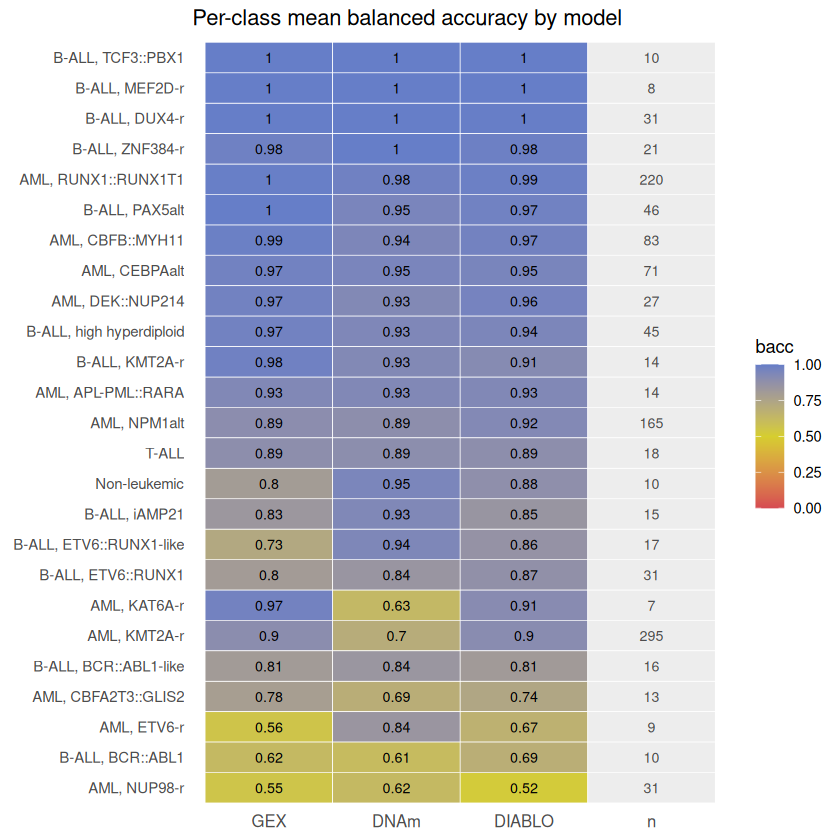

In [41]:
# Add average bacc column for sorting
bacc_wide <- bacc_wide %>%
  mutate(avg_bacc = (GEX + DNAm + DIABLO) / 3)

# Pivot to long including n_train and n_test as separate tile columns
bacc_long <- bacc_wide %>%
  pivot_longer(cols = c("GEX", "DNAm", "DIABLO"),
               names_to = "Model", values_to = "bacc")

# Create n_train and n_test rows as separate "columns"
n_df <- bacc_wide %>%
  select(Class, n_samples, avg_bacc) %>%
  pivot_longer(cols = c("n_samples"),
               names_to = "Model", values_to = "n_val") %>%
  mutate(bacc = NA)

# Combine
bacc_plot_df <- bind_rows(
  bacc_long %>% mutate(n_val = NA),
  n_df
) %>%
  mutate(Model = factor(Model,
                        levels = c("GEX", "DNAm", "DIABLO",
                                   "n_samples")))

ggplot(bacc_plot_df,
       aes(x = Model,
           y = reorder(Class, avg_bacc),
           fill = bacc)) +
  geom_tile(colour = "white") +
  # bacc values
  geom_text(data = filter(bacc_plot_df, Model %in% c("GEX","DNAm","DIABLO")),
            aes(label = round(bacc, 2)), size = 3) +
  # n_train and n_test values
  geom_text(data = filter(bacc_plot_df, Model %in% c("n_samples")),
            aes(label = n_val), size = 3, colour = "grey30") +
  scale_fill_gradient2(low       = RED,
                       mid       = YELLOW,
                       high      = BLUE,
                       midpoint  = 0.5,
                       limits    = c(0, 1),
                       na.value  = "grey93",
                       name      = "bacc") +
  scale_x_discrete(labels = c("GEX", "DNAm", "DIABLO",
                               "n")) +
  labs(title = "Per-class mean balanced accuracy by model",
       x = NULL, y = NULL) +
  theme_minimal() +
  theme(axis.text.x  = element_text(size = 10),
        axis.text.y  = element_text(size = 9),
        legend.position = "right",
        panel.grid   = element_blank())

  # Save as svg
ggsave(file.path(REPORT_OUTPUT_DIR, "per_class_bacc_plot.svg"),
       width = 5, height = 6, units = "in")

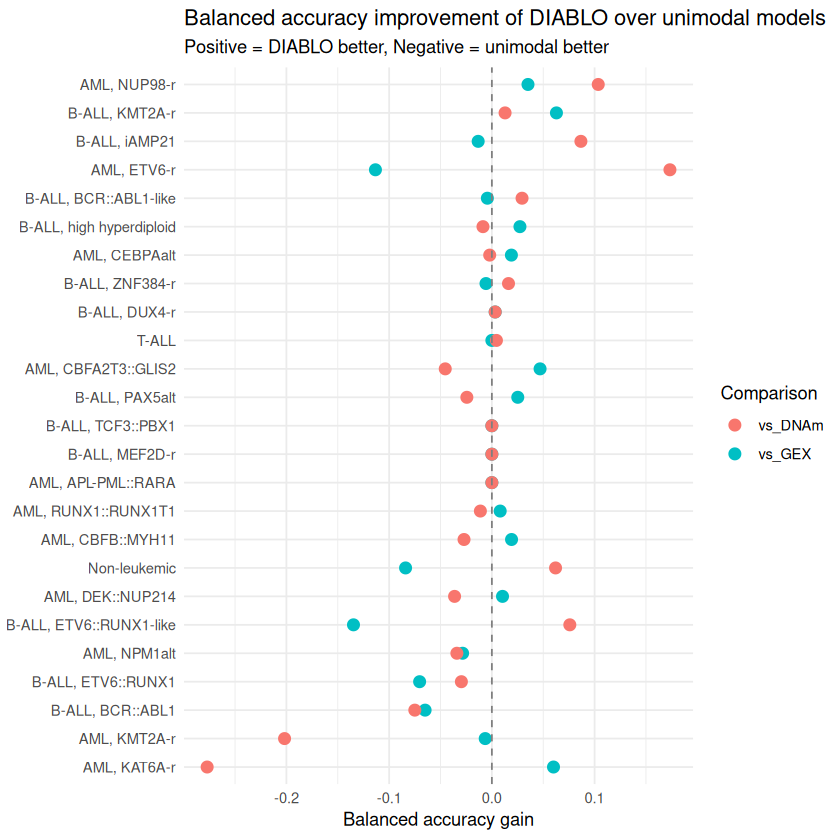

In [23]:

# ============================================================
# 2. Dot plot — improvement of DIABLO over unimodal
# ============================================================
improve_df <- data.frame(
  Class   = names(gex_ber),
  vs_GEX  = as.numeric(diablo_ber) - as.numeric(gex_ber),   # flipped vs before
  vs_DNAm = as.numeric(diablo_ber) - as.numeric(dnam_ber)
) |>
  pivot_longer(cols = c("vs_GEX","vs_DNAm"),
               names_to  = "Comparison",
               values_to = "BalAcc_improvement")

ggplot(improve_df, aes(x = BalAcc_improvement,
                       y = reorder(Class, BalAcc_improvement),
                       colour = Comparison)) +
  geom_point(size = 3) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey50") +
  labs(title    = "Balanced accuracy improvement of DIABLO over unimodal models",
       subtitle = "Positive = DIABLO better, Negative = unimodal better",
       x = "Balanced accuracy gain", y = NULL) +
  theme_minimal()


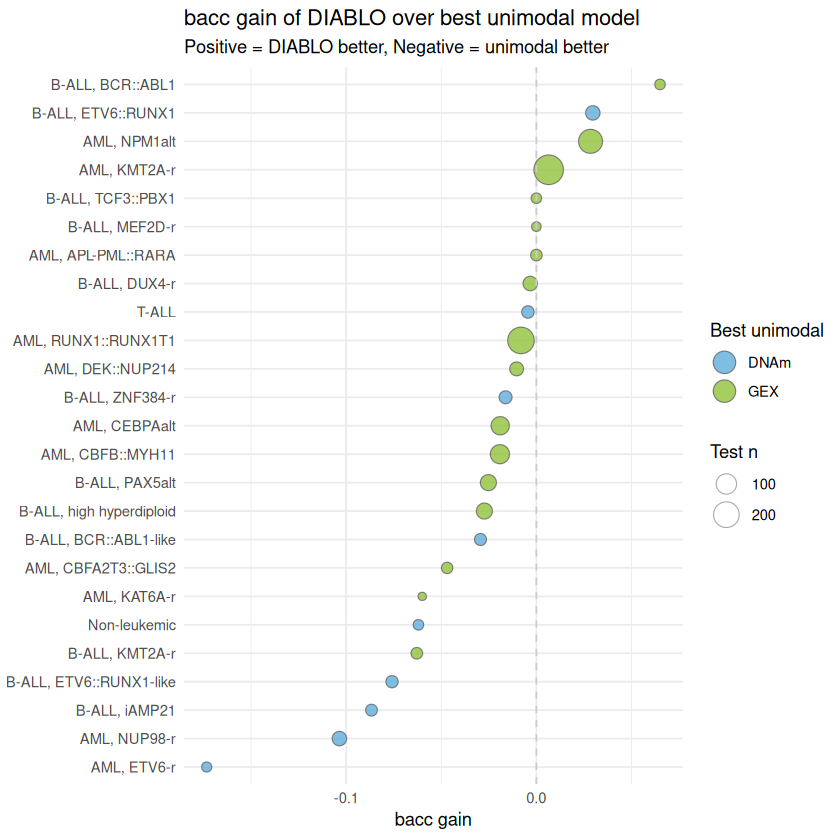

In [24]:
bacc_wide <- bacc_wide |>
  mutate(
    Best_unimodal    = pmax(GEX, DNAm),
    DIABLO_gain      = DIABLO - Best_unimodal,
    Best_unimodal_name = ifelse(GEX >= DNAm, "GEX", "DNAm")
  )

ggplot(bacc_wide, aes(x = DIABLO_gain,
                    y = reorder(Class, DIABLO_gain),
                    fill = Best_unimodal_name,
                    size = n_samples)) +
  geom_point(shape = 21, alpha = 0.8, colour = "grey40", stroke = 0.5) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey80") +
  scale_fill_manual(values = c(GEX = GREEN, DNAm = LIGHTBLUE), name = "Best unimodal") +
  scale_size_continuous(range = c(2, 8), name = "Test n") +
  guides(
    fill = guide_legend(override.aes = list(size = 6, stroke = 0.5, colour = "grey40")),
    size = guide_legend(override.aes = list(colour = "grey60", stroke = 0.5))
  ) +
  labs(title    = "bacc gain of DIABLO over best unimodal model",
       subtitle = "Positive = DIABLO better, Negative = unimodal better",
       x = "bacc gain", y = NULL) +
  theme_minimal()
  # Save as svg
ggsave(file.path(REPORT_OUTPUT_DIR, "diablo_gain_plot.svg"),
       width = 8, height = 6, units = "in")

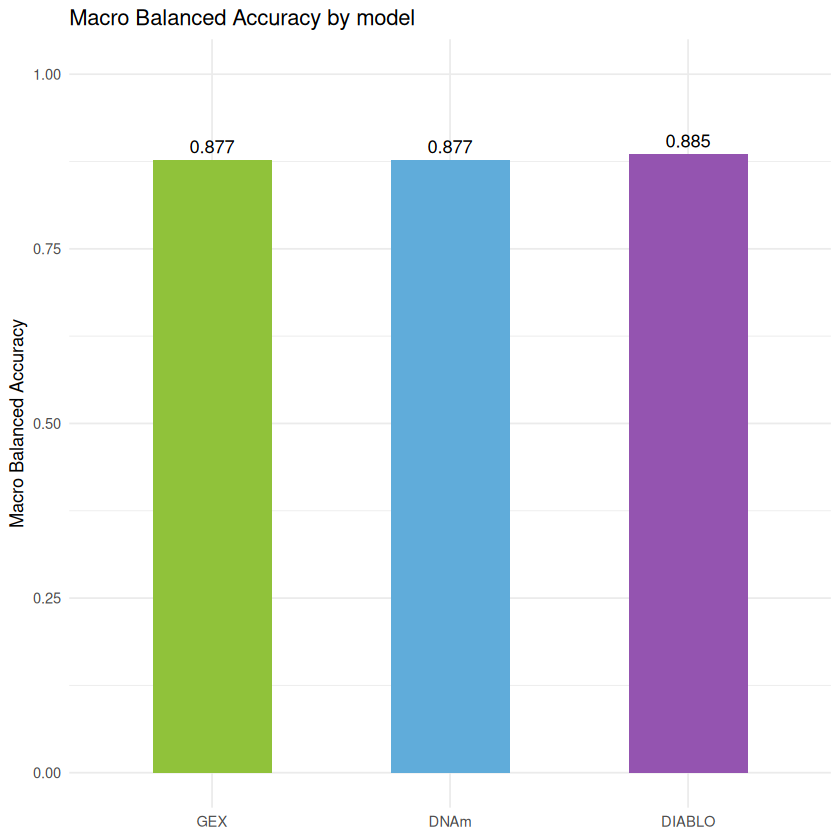

In [34]:
# Calculate macro bacc for each model
macro_bacc <- bacc_long |>
  group_by(Model) |>
  summarise(MacroBacc = mean(bacc), .groups = "drop")

ggplot(macro_bacc, aes(x = reorder(Model, MacroBacc), y = MacroBacc, fill = Model)) +
  geom_bar(stat = "identity", width = 0.5) +
  geom_text(aes(label = round(MacroBacc, 3)), vjust = -0.5) +
  scale_fill_manual(values = c(GEX = GREEN,
                                DNAm = LIGHTBLUE,
                                DIABLO = PURPLE)) +
  ylim(0, 1) +
  labs(title = "Macro Balanced Accuracy by model", x = NULL, y = "Macro Balanced Accuracy") +
  theme_minimal() +
  theme(legend.position = "none")

  ggsave(file.path(REPORT_OUTPUT_DIR, "macro_bacc_plot.svg"),
       width = 4, height = 3, units = "in")

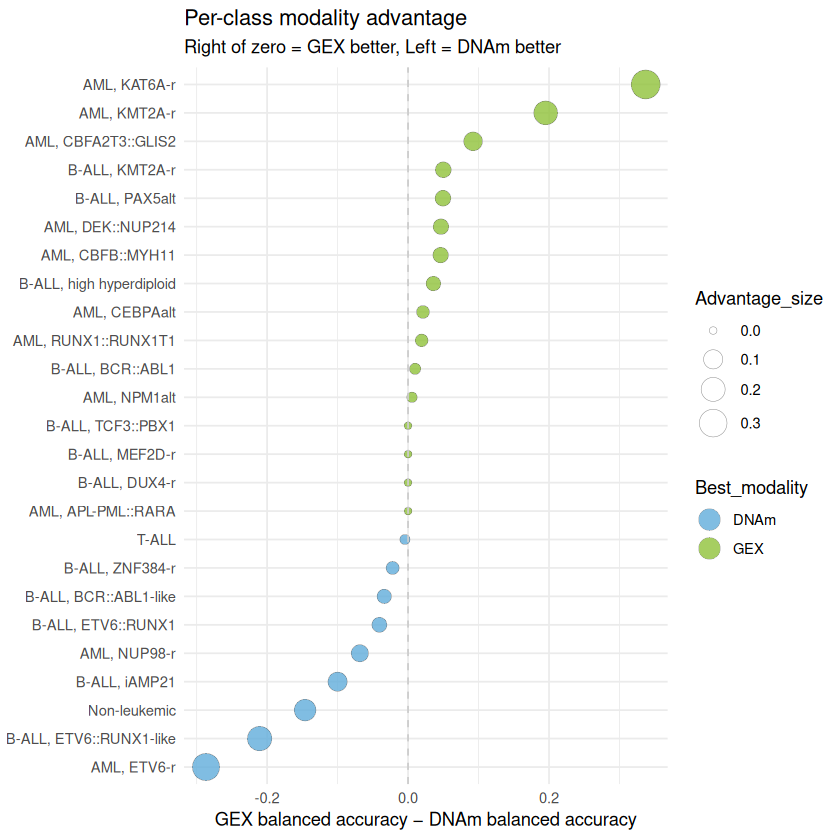

In [39]:
# Using bacc_wide from earlier
complement_df <- data.frame(
  Class = bacc_wide$Class,
  GEX   = bacc_wide$GEX,
  DNAm  = bacc_wide$DNAm
) |>
  mutate(
    GEX_advantage  = GEX - DNAm,
    Best_modality  = ifelse(GEX >= DNAm, "GEX", "DNAm"),
    Advantage_size = abs(GEX - DNAm)
  )

ggplot(complement_df,
       aes(x = GEX_advantage,
           y = reorder(Class, GEX_advantage),
           fill = Best_modality,
           size = Advantage_size)) +
  geom_point(shape = 21, alpha = 0.8, colour = "grey40", stroke = 0.2) +
  geom_vline(xintercept = 0, linetype = "dashed", colour = "grey80") +
  scale_fill_manual(values = c(GEX = GREEN, DNAm = LIGHTBLUE)) +
  scale_size_continuous(range = c(2, 8)) +
  guides(fill = guide_legend(override.aes = list(colour = "grey60", size = 6))) +
  labs(title    = "Per-class modality advantage",
       subtitle = "Right of zero = GEX better, Left = DNAm better",
       x = "GEX balanced accuracy − DNAm balanced accuracy",
       y = NULL) +
  theme_minimal()

  # Save as svg
ggsave(file.path(REPORT_OUTPUT_DIR, "per_class_modality_advantage_plot_by_advantage_size.svg"),
       width = 6, height = 6, units = "in")

In [27]:
# ============================================================
# Overall summary
# ============================================================
overall <- data.frame(
  Model        = c("GEX", "DNAm", "DIABLO"),
  Mean_BalAcc  = round(c(mean(bacc_df$GEX),
                          mean(bacc_df$DNAm),
                          mean(bacc_df$DIABLO)), 3),
  Median_BalAcc = round(c(median(bacc_df$GEX),
                           median(bacc_df$DNAm),
                           median(bacc_df$DIABLO)), 3),
  Min_BalAcc   = round(c(min(bacc_df$GEX),
                          min(bacc_df$DNAm),
                          min(bacc_df$DIABLO)), 3),
  Max_BalAcc   = round(c(max(bacc_df$GEX),
                          max(bacc_df$DNAm),
                          max(bacc_df$DIABLO)), 3),
  Classes_above_0.5 = c(sum(bacc_df$GEX    > 0.5),
                         sum(bacc_df$DNAm   > 0.5),
                         sum(bacc_df$DIABLO > 0.5))
)
print(overall)

# ============================================================
# How many classes does DIABLO win/tie/lose vs each unimodal?
# ============================================================
cat("\n=== DIABLO vs GEX ===\n")
cat("DIABLO better: ", sum(bacc_df$DIABLO >  bacc_df$GEX),  "\n")
cat("Tied:          ", sum(bacc_df$DIABLO == bacc_df$GEX),  "\n")
cat("GEX better:    ", sum(bacc_df$DIABLO <  bacc_df$GEX),  "\n")

cat("\n=== DIABLO vs DNAm ===\n")
cat("DIABLO better: ", sum(bacc_df$DIABLO >  bacc_df$DNAm), "\n")
cat("Tied:          ", sum(bacc_df$DIABLO == bacc_df$DNAm), "\n")
cat("DNAm better:   ", sum(bacc_df$DIABLO <  bacc_df$DNAm), "\n")

# ============================================================
# Wilcoxon signed-rank test — is DIABLO significantly better?
# ============================================================
cat("\n=== Wilcoxon signed-rank test ===\n")
wt_gex  <- wilcox.test(bacc_df$DIABLO, bacc_df$GEX,
                        paired = TRUE, alternative = "greater")
wt_dnam <- wilcox.test(bacc_df$DIABLO, bacc_df$DNAm,
                        paired = TRUE, alternative = "greater")

cat("DIABLO vs GEX  p-value:", round(wt_gex$p.value,  4), "\n")
cat("DIABLO vs DNAm p-value:", round(wt_dnam$p.value, 4), "\n")

   Model Mean_BalAcc Median_BalAcc Min_BalAcc Max_BalAcc Classes_above_0.5
1    GEX       0.877         0.929      0.555          1                25
2   DNAm       0.877         0.929      0.612          1                25
3 DIABLO       0.885         0.913      0.520          1                25

=== DIABLO vs GEX ===
DIABLO better:  10 
Tied:           4 
GEX better:     11 

=== DIABLO vs DNAm ===


DIABLO better:  12 
Tied:           3 
DNAm better:    10 

=== Wilcoxon signed-rank test ===


Warning message in wilcox.test.default(bacc_df$DIABLO, bacc_df$GEX, paired = TRUE, :
“cannot compute exact p-value with zeroes”
Warning message in wilcox.test.default(bacc_df$DIABLO, bacc_df$DNAm, paired = TRUE, :
“cannot compute exact p-value with zeroes”


DIABLO vs GEX  p-value: 0.4039 
DIABLO vs DNAm p-value: 0.3851 


In [28]:
# Is DIABLO at least consistently competitive? (not worse)
wt_gex_two  <- wilcox.test(bacc_df$DIABLO, bacc_df$GEX,  paired = TRUE)
wt_dnam_two <- wilcox.test(bacc_df$DIABLO, bacc_df$DNAm, paired = TRUE)
cat("Two-sided DIABLO vs GEX  p-value:", round(wt_gex_two$p.value,  4), "\n")
cat("Two-sided DIABLO vs DNAm p-value:", round(wt_dnam_two$p.value, 4), "\n")

Warning message in wilcox.test.default(bacc_df$DIABLO, bacc_df$GEX, paired = TRUE):
“cannot compute exact p-value with zeroes”
Warning message in wilcox.test.default(bacc_df$DIABLO, bacc_df$DNAm, paired = TRUE):
“cannot compute exact p-value with zeroes”


Two-sided DIABLO vs GEX  p-value: 0.8078 
Two-sided DIABLO vs DNAm p-value: 0.7701 


In [29]:
# Compare DNAm with GEX as well
wt_dnam_gex <- wilcox.test(bacc_df$DNAm, bacc_df$GEX, paired = TRUE)
cat("Two-sided DNAm vs GEX p-value:", round(wt_dnam_gex$p.value, 4), "\n")

Warning message in wilcox.test.default(bacc_df$DNAm, bacc_df$GEX, paired = TRUE):
“cannot compute exact p-value with zeroes”


Two-sided DNAm vs GEX p-value: 0.8348 


In [30]:
# For each class, take the better of GEX or DNAm
oracle_bacc <- pmax(bacc_df$GEX, bacc_df$DNAm)

oracle_summary <- data.frame(
  Model       = c("GEX", "DNAm", "DIABLO", "Oracle (best unimodal)"),
  Mean_BalAcc = round(c(mean(bacc_df$GEX),
                         mean(bacc_df$DNAm),
                         mean(bacc_df$DIABLO),
                         mean(oracle_bacc)), 3)
)
print(oracle_summary)

# Which modality wins per class?
bacc_df$Best_modality <- ifelse(bacc_df$GEX >= bacc_df$DNAm, "GEX", "DNAm")
print(bacc_df[, c("Class", "GEX", "DNAm", "Best_modality")])

                   Model Mean_BalAcc
1                    GEX       0.877
2                   DNAm       0.877
3                 DIABLO       0.885
4 Oracle (best unimodal)       0.913
                      Class       GEX      DNAm Best_modality
1        AML, APL-PML::RARA 0.9285714 0.9285714           GEX
2       AML, CBFA2T3::GLIS2 0.7846154 0.6923077           GEX
3          AML, CBFB::MYH11 0.9879518 0.9416867           GEX
4             AML, CEBPAalt 0.9718310 0.9507042           GEX
5          AML, DEK::NUP214 0.9725926 0.9259259           GEX
6               AML, ETV6-r 0.5555556 0.8422222          DNAm
7              AML, KAT6A-r 0.9685714 0.6314286           GEX
8              AML, KMT2A-r 0.8979661 0.7026441           GEX
9              AML, NPM1alt 0.8945455 0.8889697           GEX
10             AML, NUP98-r 0.5548387 0.6232258          DNAm
11      AML, RUNX1::RUNX1T1 0.9954545 0.9761818           GEX
12         B-ALL, BCR::ABL1 0.6220000 0.6120000           GEX
13    B-A